## Proyecto ML

Predicción de accesos fijos a Internet en los municipios de Colombia mediante Regresión Lineal

## Problema de investigación

En Colombia, la calidad del internet fijo no es igual en todo el territorio.
¿En qué departamentos se contratan las mayores velocidades de bajada y subida,
y qué tanto dependen esas velocidades del estrato socioeconómico y de la
tecnología de acceso?

## Objetivo general

Identificar los departamentos con mejor internet fijo y determinar qué factores
(ubicación, estrato y tecnología) explican las diferencias de velocidad,
mediante un modelo de regresión lineal.

## Preguntas específicas

1. ¿Qué departamentos tienen la mayor velocidad promedio de bajada y de subida,
   ponderada por número de accesos?
2. ¿Cómo cambia la velocidad contratada entre estratos 1 a 6 en el segmento
   residencial?
3. ¿Qué tecnología (fibra óptica, cable, WiFi, etc.) se asocia con mayores
   velocidades, una vez se controla por departamento y estrato?
4. ¿Qué pesa más para explicar la velocidad: el departamento, el estrato o la
   tecnología?
5. ¿Cómo evolucionó la velocidad promedio entre 2023 y 2026, y se redujo la
   brecha entre departamentos?

## Variable a predecir (Y)

VELOCIDAD_BAJADA (Mbps).

## Variables explicativas (X)

DEPARTAMENTO, ESTRATO, TECNOLOGIA, ANNO, TRIMESTRE

## Tipo de aprendizaje

Supervisado

## Tipo de problema

Regresión

## Algoritmo

Regresión lineal múltiple con variables categóricas codificadas (one-hot)

1. Preparacion de Datos ML

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer

In [3]:

from google.colab import files
import pandas as pd
import io

archivo = files.upload()
nombre = next(iter(archivo))

df = pd.read_csv(io.BytesIO(archivo[nombre]))
display(df.head())
print("Datos cargados:", df.shape)


Saving Accesos_a_Internet_corregido.csv to Accesos_a_Internet_corregido.csv


,ANNO,TRIMESTRE,PROVEEDOR,CODIGO_DANE_DEPARTAMENTO,DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,MUNICIPIO,SEGMENTO,TECNOLOGIA,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET
0,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),50.0,25.0,1
1,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),40.0,20.0,4
2,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),15.0,7.5,5
3,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),30.0,15.0,4
4,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),20.0,10.0,4


Datos cargados: (2072381, 12)


In [7]:
df = pd.read_csv('Accesos_a_Internet_corregido.csv')
df

,ANNO,TRIMESTRE,PROVEEDOR,CODIGO_DANE_DEPARTAMENTO,DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,MUNICIPIO,SEGMENTO,TECNOLOGIA,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET
0,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),50.0,25.0,1
1,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),40.0,20.0,4
2,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),15.0,7.5,5
3,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),30.0,15.0,4
4,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),20.0,10.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
2072376,2026,2,ZUMA COMUNICACIONES DE COLOMBIA S.A.S,25,CUNDINAMARCA,25899,ZIPAQUIRÁ,RESIDENCIAL - ESTRATO 4,FIBER TO THE HOME (FTTH),600.0,600.0,49
2072377,2026,2,ZUMA COMUNICACIONES DE COLOMBIA S.A.S,25,CUNDINAMARCA,25899,ZIPAQUIRÁ,RESIDENCIAL - ESTRATO 4,FIBER TO THE HOME (FTTH),250.0,250.0,16
2072378,2026,2,ZUMA COMUNICACIONES DE COLOMBIA S.A.S,25,CUNDINAMARCA,25899,ZIPAQUIRÁ,RESIDENCIAL - ESTRATO 4,FIBER TO THE HOME (FTTH),700.0,700.0,35
2072379,2026,2,ZUMA COMUNICACIONES DE COLOMBIA S.A.S,25,CUNDINAMARCA,25899,ZIPAQUIRÁ,RESIDENCIAL - ESTRATO 4,FIBER TO THE HOME (FTTH),200.0,200.0,42


In [ ]:
# Tipos de datos y valores nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2072381 entries, 0 to 2072380
Data columns (total 12 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   ANNO                      int64  
 1   TRIMESTRE                 int64  
 2   PROVEEDOR                 object 
 3   CODIGO_DANE_DEPARTAMENTO  int64  
 4   DEPARTAMENTO              object 
 5   CODIGO_DANE_MUNICIPIO     int64  
 6   MUNICIPIO                 object 
 7   SEGMENTO                  object 
 8   TECNOLOGIA                object 
 9   VELOCIDAD_BAJADA          float64
 10  VELOCIDAD_SUBIDA          float64
 11  ACCESOS_FIJOS_INTERNET    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 189.7+ MB


El conjunto original tiene 2.072.381 registros y 12 variables, 5 enteras, 2 decimales y 5 de texto. aqui se confirma que no hay valores nulos, por lo que no fue necesario imputar datos, la variable objetivo (VELOCIDAD_BAJADA) es numérica continua, adecuada para un problema de regresión.

In [ ]:
# Estadísticas descriptivas
df.describe()

,ANNO,TRIMESTRE,CODIGO_DANE_DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET
count,2.072381e+06,2.072381e+06,2.072381e+06,2.072381e+06,2.072381e+06,2.072381e+06,2.072381e+06
mean,2.024638e+03,2.428881e+00,3.679611e+01,3.710640e+04,3.483670e+02,2.593624e+02,5.148360e+01
std,9.046468e-01,1.156468e+00,2.675297e+01,2.673574e+04,5.392116e+03,4.393999e+03,7.215350e+02
min,2.023000e+03,1.000000e+00,5.000000e+00,5.001000e+03,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.024000e+03,1.000000e+00,1.500000e+01,1.500100e+04,1.600000e+01,1.000000e+01,1.000000e+00
50%,2.025000e+03,2.000000e+00,2.500000e+01,2.548800e+04,1.000000e+02,3.000000e+01,3.000000e+00
75%,2.025000e+03,4.000000e+00,6.600000e+01,6.617000e+04,3.000000e+02,1.000000e+02,1.100000e+01
max,2.026000e+03,4.000000e+00,9.900000e+01,9.977300e+04,9.950000e+05,9.950000e+05,2.106460e+05


In [ ]:
# Análisis de nulos por columna
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(1)

resumen = pd.DataFrame({
    'nulos': nulos,
    'porcentaje_nulos': porcentaje
})

# Mostrar solo columnas que tienen nulos
resumen_con_nulos = resumen[resumen['nulos'] > 0]

if len(resumen_con_nulos) == 0:
    print(' No hay valores nulos en el dataset')
else:
    print('Columnas con nulos:')
    display(resumen_con_nulos)

 No hay valores nulos en el dataset


Con un tamaño 2072381 registros y 12 variables entre el 4T de 2023 y el 2T de 2026, de las cuales no hay valores nulos

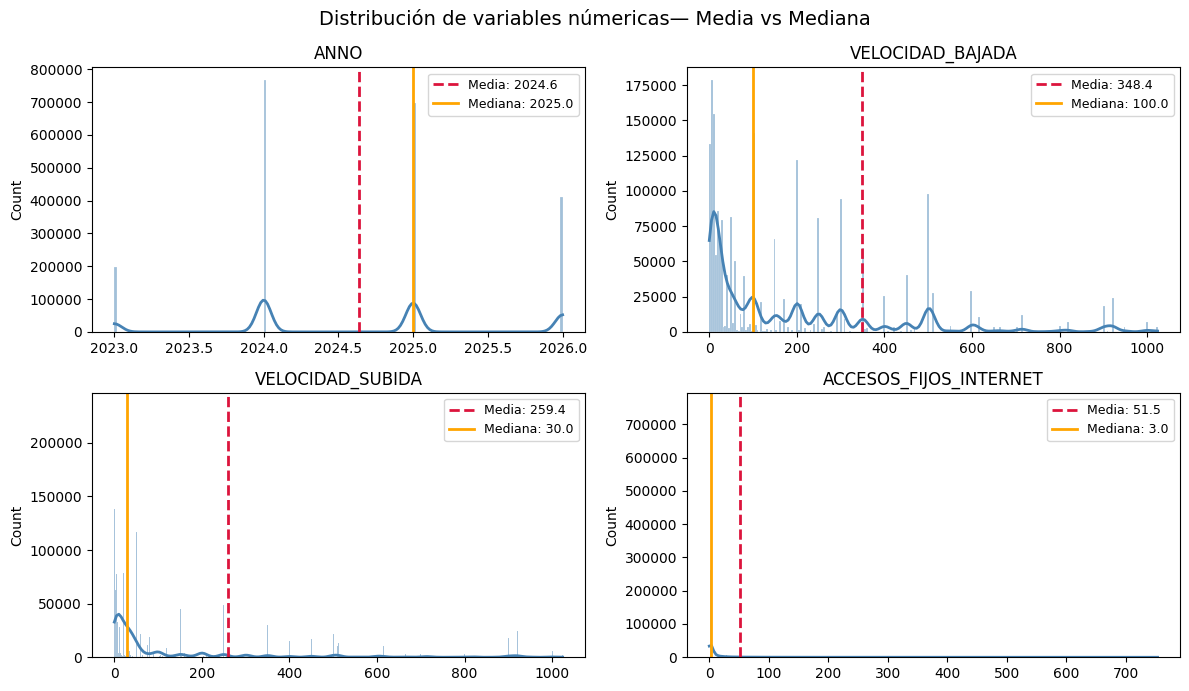

In [ ]:
columnas = ['ANNO', 'VELOCIDAD_BAJADA', 'VELOCIDAD_SUBIDA', 'ACCESOS_FIJOS_INTERNET']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, col in enumerate(columnas):
    datos = df[col].dropna()
    media   = datos.mean()
    mediana = datos.median()

    # Para dibujar se recorta en el percentil 99 (media y mediana usan todos los datos)
    datos_plot = datos[datos <= datos.quantile(0.99)]

    # Histograma + KDE
    sns.histplot(datos_plot, ax=axes[i], kde=True, color='steelblue',
                 edgecolor='white', line_kws={'linewidth': 2})

    # Línea de media
    axes[i].axvline(media, color='crimson', linewidth=2,
                    linestyle='--', label=f'Media: {media:.1f}')

    # Línea de mediana
    axes[i].axvline(mediana, color='orange', linewidth=2,
                    linestyle='-', label=f'Mediana: {mediana:.1f}')

    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel('')
    axes[i].legend(fontsize=9)

plt.suptitle('Distribución de variables númericas— Media vs Mediana', fontsize=14)
plt.tight_layout()
plt.show()

- los registros de ANNO se concentran en picos alrededor de 2024 y 2025, con menos observaciones en 2023 y 2026, Esto es coherente con que la serie inicia en el cuarto trimestre de 2023 y termina en el segundo de 2026 con una media (2024,6) y mediana (2025,0) son cercanas.

- En velocidad de bajada la media (348,4 Mbps) es mucho mayor que la mediana (100 Mbps), la distribución es asimétrica a la derecha: la mayoría de los registros están en velocidades bajas y pocos alcanzan velocidades altas, los picos recurrentes (50, 100, 200, 300, 500 Mbps) reflejan que las velocidades se contratan en planes comerciales discretos.

- En la velocidad de subuda la media de 259,4 Mbps frente a mediana de 30 Mbps. Es el mismo patrón asimétrico, pero con una subida generalmente menor que la bajada.

- ahora en los accesos fijos de internet la media de 51,5 frente a mediana de 3. La mayoría de los registros tienen pocos accesos, mientras que unos pocos concentran un volumen muy alto.

In [ ]:
# Ver categorías
print('Departamentos:', sorted(df['DEPARTAMENTO'].unique()))
print('Tecnologías:', sorted(df['TECNOLOGIA'].unique()))
print('Segmentos:', df['SEGMENTO'].unique())

Departamentos: ['AMAZONAS', 'ANTIOQUIA', 'ARAUCA', 'ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA', 'ATLÁNTICO', 'BOGOTÁ D.C.', 'BOLÍVAR', 'BOYACÁ', 'CALDAS', 'CAQUETA', 'CASANARE', 'CAUCA', 'CESAR', 'CHOCÓ', 'CUNDINAMARCA', 'CÓRDOBA', 'GUAINÍA', 'GUAVIARE', 'HUILA', 'LA GUAJIRA', 'MAGDALENA', 'META', 'NARIÑO', 'NORTE DE SANTANDER', 'PUTUMAYO', 'QUINDÍO', 'RISARALDA', 'SANTANDER', 'SUCRE', 'TOLIMA', 'VALLE DEL CAUCA', 'VAUPÉS', 'VICHADA']
Tecnologías: ['5G FWA', 'CABLE', 'FIBER TO THE ANTENNA (FTTA)', 'FIBER TO THE BUILDING O FIBER TO THE BASEMENT (FTTB)', 'FIBER TO THE CABINET (FTTC)', 'FIBER TO THE HOME (FTTH)', 'FIBER TO THE NODE (FTTN)', 'FIBER TO THE PREMISES', 'HYBRID FIBER COAXIAL (HFC)', 'NA (NO APLICA)', 'OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX)', 'OTRAS TECNOLOGÍAS FIJAS', 'OTRAS TECNOLOGÍAS INALÁMBRICAS', 'SATELITAL', 'SATELITAL LEO', 'WIFI', 'WIMAX', 'XDSL']
Segmentos: ['RESIDENCIAL - ESTRATO 2' 'CORPORATIVO' 'RESIDENCIAL - ESTRATO 1'
 'RESIDENCIAL - ESTRATO 3' 'R

El dataset incluye 33 departamentos, 18 tecnologías y 10 segmentos, al conservar solo los segmentos residenciales quedaron 1.434.378 registros (aproximadamente el 69 % del total), con los estratos 1 a 6 y sin nulos, ESTRATO se convirtió a valores numéricos de 1 a 6, lo que conserva el orden natural de la variable.

In [ ]:
# Nos quedarnos solo con el segmento residencial porques es el único que tiene estrato
df = df[df['SEGMENTO'].str.startswith('RESIDENCIAL')].copy()

# Extraemos el estrato del texto: "RESIDENCIAL - ESTRATO 2" -> "ESTRATO 2"
df['ESTRATO'] = df['SEGMENTO'].str.replace('RESIDENCIAL - ', '', regex=False)

print('Estratos:', sorted(df['ESTRATO'].unique()))
print(df.shape)

Estratos: ['ESTRATO 1', 'ESTRATO 2', 'ESTRATO 3', 'ESTRATO 4', 'ESTRATO 5', 'ESTRATO 6']
(1434378, 13)


## Mapeo manual: variable ordinal (ESTRATO)

In [ ]:
df['ESTRATO'] = df['ESTRATO'].map({
    'ESTRATO 1': 1,
    'ESTRATO 2': 2,
    'ESTRATO 3': 3,
    'ESTRATO 4': 4,
    'ESTRATO 5': 5,
    'ESTRATO 6': 6
})

print('Valores únicos de estrato:', sorted(df['ESTRATO'].unique()))
print('Nulos en ESTRATO:', df['ESTRATO'].isna().sum())
df.head(5)

Valores únicos de estrato: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Nulos en ESTRATO: 0


,ANNO,TRIMESTRE,PROVEEDOR,CODIGO_DANE_DEPARTAMENTO,DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,MUNICIPIO,SEGMENTO,TECNOLOGIA,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET,ESTRATO
0,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),50.0,25.0,1,2
1,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),40.0,20.0,4,2
2,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),15.0,7.5,5,2
3,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),30.0,15.0,4,2
4,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),20.0,10.0,4,2


In [ ]:
# SEGMENTO ya quedó convertido en ESTRATO; MUNICIPIO y los códigos tienen demasiadas categorías;
# PROVEEDOR no hace parte de las preguntas; VELOCIDAD_SUBIDA se omite para evitar fuga de datos
df = df.drop(columns=['SEGMENTO', 'PROVEEDOR', 'MUNICIPIO',
                      'CODIGO_DANE_DEPARTAMENTO', 'CODIGO_DANE_MUNICIPIO',
                      'VELOCIDAD_SUBIDA'])
df.columns.tolist()

['ANNO',
 'TRIMESTRE',
 'DEPARTAMENTO',
 'TECNOLOGIA',
 'VELOCIDAD_BAJADA',
 'ACCESOS_FIJOS_INTERNET',
 'ESTRATO']

Se eliminaron SEGMENTO, PROVEEDOR, MUNICIPIO, los códigos DANE y VELOCIDAD_SUBIDA, quedaron ANNO, TRIMESTRE, DEPARTAMENTO, TECNOLOGIA, ESTRATO, la variable objetivo y los accesos, coon el One-Hot Encoding (drop_first=True) el conjunto pasó a 54 columnas, donde cada departamento y tecnología se representa con una columna binaria (0 o 1).

## One-Hot Encoding: variables nominales (DEPARTAMENTO y TECNOLOGIA)

In [ ]:
df = pd.get_dummies(df, columns=['DEPARTAMENTO', 'TECNOLOGIA'], drop_first=True, dtype=int)

print('Columnas después del One-Hot Encoding:')
print(df.columns.tolist())
print(df.shape)
df.head(5)

Columnas después del One-Hot Encoding:
['ANNO', 'TRIMESTRE', 'VELOCIDAD_BAJADA', 'ACCESOS_FIJOS_INTERNET', 'ESTRATO', 'DEPARTAMENTO_ANTIOQUIA', 'DEPARTAMENTO_ARAUCA', 'DEPARTAMENTO_ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA', 'DEPARTAMENTO_ATLÁNTICO', 'DEPARTAMENTO_BOGOTÁ D.C.', 'DEPARTAMENTO_BOLÍVAR', 'DEPARTAMENTO_BOYACÁ', 'DEPARTAMENTO_CALDAS', 'DEPARTAMENTO_CAQUETA', 'DEPARTAMENTO_CASANARE', 'DEPARTAMENTO_CAUCA', 'DEPARTAMENTO_CESAR', 'DEPARTAMENTO_CHOCÓ', 'DEPARTAMENTO_CUNDINAMARCA', 'DEPARTAMENTO_CÓRDOBA', 'DEPARTAMENTO_GUAINÍA', 'DEPARTAMENTO_GUAVIARE', 'DEPARTAMENTO_HUILA', 'DEPARTAMENTO_LA GUAJIRA', 'DEPARTAMENTO_MAGDALENA', 'DEPARTAMENTO_META', 'DEPARTAMENTO_NARIÑO', 'DEPARTAMENTO_NORTE DE SANTANDER', 'DEPARTAMENTO_PUTUMAYO', 'DEPARTAMENTO_QUINDÍO', 'DEPARTAMENTO_RISARALDA', 'DEPARTAMENTO_SANTANDER', 'DEPARTAMENTO_SUCRE', 'DEPARTAMENTO_TOLIMA', 'DEPARTAMENTO_VALLE DEL CAUCA', 'DEPARTAMENTO_VAUPÉS', 'DEPARTAMENTO_VICHADA', 'TECNOLOGIA_CABLE', 'TECNOLOGIA_FIBER TO

,ANNO,TRIMESTRE,VELOCIDAD_BAJADA,ACCESOS_FIJOS_INTERNET,ESTRATO,DEPARTAMENTO_ANTIOQUIA,DEPARTAMENTO_ARAUCA,"DEPARTAMENTO_ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",DEPARTAMENTO_ATLÁNTICO,DEPARTAMENTO_BOGOTÁ D.C.,...,TECNOLOGIA_HYBRID FIBER COAXIAL (HFC),TECNOLOGIA_NA (NO APLICA),TECNOLOGIA_OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),TECNOLOGIA_OTRAS TECNOLOGÍAS FIJAS,TECNOLOGIA_OTRAS TECNOLOGÍAS INALÁMBRICAS,TECNOLOGIA_SATELITAL,TECNOLOGIA_SATELITAL LEO,TECNOLOGIA_WIFI,TECNOLOGIA_WIMAX,TECNOLOGIA_XDSL
0,2023,4,50.0,1,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2023,4,40.0,4,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2023,4,15.0,5,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2023,4,30.0,4,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2023,4,20.0,4,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


##  Verificar la transformación de los datos

In [ ]:
print('Tipos de datos:')
print(df.dtypes)
print()
print('Nulos:', df.isnull().sum().to_dict())
print('Columnas con texto:', df.select_dtypes(include=['object', 'string', 'category']).columns.tolist())
print('Columnas booleanas:', df.select_dtypes(include='bool').columns.tolist())

sin_nulos = df.isnull().sum().sum() == 0
sin_texto = len(df.select_dtypes(include=['object', 'string', 'category']).columns) == 0
sin_bool  = len(df.select_dtypes(include='bool').columns) == 0

if sin_nulos and sin_texto and sin_bool:
    print('\n Todo listo — sin NaN, sin texto, sin booleanos')
else:
    print('\n Aún hay problemas — revisar antes de continuar')

Tipos de datos:
ANNO                                                                       int64
TRIMESTRE                                                                  int64
VELOCIDAD_BAJADA                                                         float64
ACCESOS_FIJOS_INTERNET                                                     int64
ESTRATO                                                                    int64
DEPARTAMENTO_ANTIOQUIA                                                     int64
DEPARTAMENTO_ARAUCA                                                        int64
DEPARTAMENTO_ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA      int64
DEPARTAMENTO_ATLÁNTICO                                                     int64
DEPARTAMENTO_BOGOTÁ D.C.                                                   int64
DEPARTAMENTO_BOLÍVAR                                                       int64
DEPARTAMENTO_BOYACÁ                                                        int64
DEPARTAMENTO

Se verifica que los datos quedaron listos para entrenar el modelo. El código revisa tres cosas: los tipos de datos de cada columna, la presencia de valores nulos y la existencia de columnas de texto o booleanas, que los algoritmos de regresión no pueden procesar directamente, todas las columnas quedaron numéricas (int64 y una float64), sin nulos, sin texto y sin booleanos, la verificación confirmó que el conjunto de datos quedó completamente numérico y sin valores faltantes, por lo que esta en condiciones de dividirse en entrenamiento y prueba y alimentar el modelo de regresión lineal.

##  División Train / Test

In [ ]:
# Limpiamos los valores extremos antes de dividir
# Se eliminan velocidades de 0 (sin servicio de internet) y mayores a 1000 Mbps (probables errores de reporte)
print('Filas antes del filtro:', df.shape[0])
df = df[(df['VELOCIDAD_BAJADA'] > 0) & (df['VELOCIDAD_BAJADA'] <= 1000)].copy()
print('Filas después del filtro:', df.shape[0])

# Separar X e y
# ACCESOS_FIJOS_INTERNET se deja fuera de X: describe cuántos usuarios hay, no el tipo de internet
X = df.drop(['VELOCIDAD_BAJADA', 'ACCESOS_FIJOS_INTERNET'], axis=1)
y = df['VELOCIDAD_BAJADA']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 80% train, 20% test
    random_state=42     # misma división siempre
)

print(f' Train: {X_train.shape}  ← el modelo aprende con estos')
print(f' Test:  {X_test.shape}   ← con estos lo evaluamos')

Filas antes del filtro: 2072381
Filas después del filtro: 2048793
✅ Train: (1639034, 10)  ← el modelo aprende con estos
✅ Test:  (409759, 10)   ← con estos lo evaluamos


Al filtrar velocidades entre 0 y 1000 Mbps se pasó de 2.072.381 a 2.048.793 registros, es decir, se retiró cerca del 1,1 % de los datos, la partición 80/20 dejó 1.639.034 registros para entrenamiento y 409.759 para prueba, con random_state=42 para que la división sea reproducible.

## Escalado de Variables

In [ ]:
# Solo escalar columnas numéricas continuas
cols_escalar = ['ANNO', 'TRIMESTRE']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()

#  fit_transform en train, solo transform en test
X_train_scaled[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test_scaled[cols_escalar]  = scaler.transform(X_test[cols_escalar])

print(' Escalado completado')
X_train_scaled.head(3)

✅ Escalado completado


,ANNO,TRIMESTRE,PROVEEDOR,CODIGO_DANE_DEPARTAMENTO,DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,MUNICIPIO,SEGMENTO,TECNOLOGIA,VELOCIDAD_SUBIDA
1185107,0.401016,-0.370971,AZTECA COMUNICACIONES COLOMBIA S.A.S,23,CÓRDOBA,23574,PUERTO ESCONDIDO,CORPORATIVO,FIBER TO THE HOME (FTTH),22.0
979593,0.401016,-1.235483,CABLETAME S A S,85,CASANARE,85015,CHAMEZA,CORPORATIVO,FIBER TO THE HOME (FTTH),10.0
831258,-0.703571,1.358052,COMUNICACION CELULAR S A COMCEL S A,85,CASANARE,85001,YOPAL,RESIDENCIAL - ESTRATO 3,HYBRID FIBER COAXIAL (HFC),10.0


Se estandarizaron ANNO y TRIMESTRE con StandardScaler, ajustado solo con los datos de entrenamiento y aplicado luego al conjunto de prueba, para no filtrar información hacia el test, los valores escalados indican cuántas desviaciones estándar se aleja cada dato de la media, positivos si está por encima y negativos si está por debajo, por ejemplo los dos primeros registros comparten ANNO igual a 0,40 (mismo año, algo por encima del promedio), mientras que el tercero tiene ANNO igual a -0,70, es decir es de un año más temprano en TRIMESTRE, -1,24 corresponde a un trimestre bajo y 1,36 a uno alto

**Entrenamiento del modelo**

In [ ]:

from sklearn.linear_model import LinearRegression
import pandas as pd

# Eliminar columnas de texto
X_train_modelo = X_train_scaled.select_dtypes(include='number')
X_test_modelo = X_test_scaled[X_train_modelo.columns]

# Entrenar regresión lineal
modelo = LinearRegression()
modelo.fit(X_train_modelo, y_train)

print("Modelo entrenado correctamente")
print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({
    "Variable": X_train_modelo.columns,
    "Coeficiente": modelo.coef_
})

display(coeficientes.sort_values("Coeficiente", ascending=False))


Modelo entrenado correctamente
Intercepto: 133.79269779369588


,Variable,Coeficiente
2,CODIGO_DANE_DEPARTAMENTO,56.722605
0,ANNO,10.087931
1,TRIMESTRE,5.196190
4,VELOCIDAD_SUBIDA,0.582774
3,CODIGO_DANE_MUNICIPIO,-0.056800


Los coeficientes muestran el efecto de cada variable sobre la velocidad de bajada, manteniendo las demás constantes, ANNO (10,09) indica que la velocidad contratada aumenta unos 10 Mbps por cada desviación estándar del año, lo que refleja una tendencia creciente con el tiempo, TRIMESTRE (5,20) aporta un aumento menor, de unos 5 Mbps por desviación estándar, VELOCIDAD_SUBIDA (0,58) señala que por cada Mbps adicional de subida, la bajada aumenta cerca de 0,58 Mbps, lo cual es esperable porque ambas velocidades suelen ir ligadas en los planes, CODIGO_DANE_DEPARTAMENTO (56,72) es el coeficiente más alto, pero al ser un código identificador y no una medida, su valor numérico no tiene una lectura directa y al final CODIGO_DANE_MUNICIPIO (-0,06) tiene un efecto casi nulo. Por lo cual concluimos que el entrenamiento muestra que el tiempo (ANNO y TRIMESTRE) y la velocidad de subida se relacionan positivamente con la velocidad de bajada, mientras que los códigos geográficos aportan poca información interpretable al modelo

Evaluacion del **modelo**

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Usar las mismas columnas del entrenamiento
X_test_modelo = X_test_scaled[X_train_modelo.columns]

# Realizar predicciones
y_pred = modelo.predict(X_test_modelo)

# Calcular métricas
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Mostrar resultados
resultados = pd.DataFrame({
    "Metrica": ["MAE", "RMSE", "R2"],
    "Resultado": [mae, rmse, r2]
})

display(resultados.round(4))


,Metrica,Resultado
0,MAE,109.6135
1,RMSE,241.8469
2,R2,-0.2117


- El MAE fue igual a 109,61 Mbps promedio, la predicción se desvía unos 110 Mbps del valor real, un error comparable a la mediana de las velocidades (100 Mbps).

- El RMSE fue igual a 241,85 Mbps promedio, al ser más del doble del MAE, indica que existen errores grandes en algunos registros, sobre todo en velocidades altas.

- El R2 es igual a -0,2117, el modelo no logra explicar la variabilidad de la velocidad y rinde por debajo de un predictor que siempre usara la media.

**Visualizacion de los datos**

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


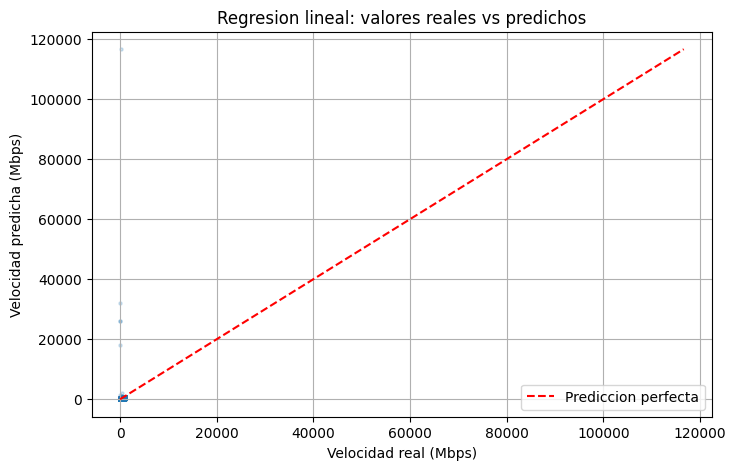

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Comparar velocidades reales y predichas
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.2, s=5)

# Linea de prediccion perfecta
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot([limite_min, limite_max],
         [limite_min, limite_max],
         'r--', label='Prediccion perfecta')

plt.xlabel('Velocidad real (Mbps)')
plt.ylabel('Velocidad predicha (Mbps)')
plt.title('Regresion lineal: valores reales vs predichos')
plt.legend()
plt.grid(True)
plt.show()


La mayoría de los puntos se agrupan cerca del origen, en el rango real de 0 a 1000 Mbps, algunas predicciones se alejan mucho hacia arriba (hasta ~116.000 Mbps, con valores reales de máximo 1000), lo que explica el RMSE elevado, la nube de puntos no sigue la línea de predicción perfecta.

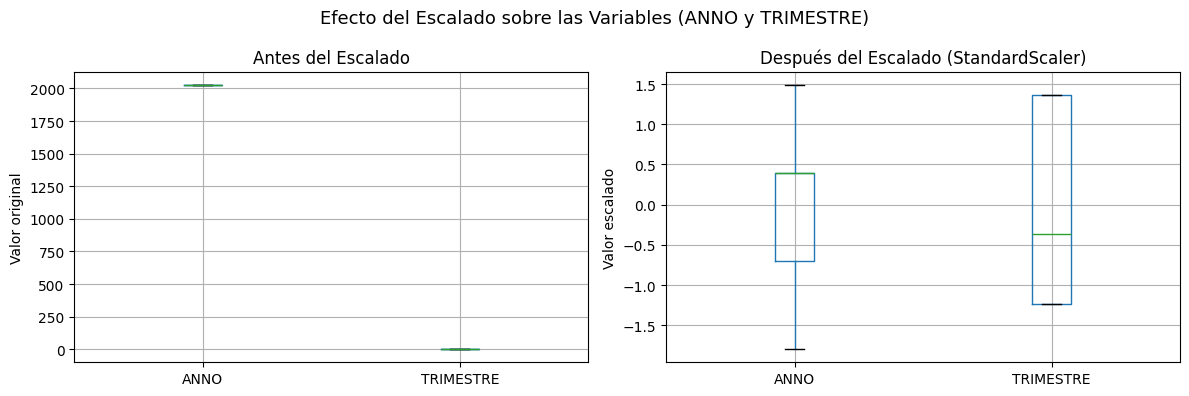

In [ ]:
# Visualizar efecto del escalado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

X_train[cols_escalar].boxplot(ax=axes[0])
axes[0].set_title('Antes del Escalado')
axes[0].set_ylabel('Valor original')

X_train_scaled[cols_escalar].boxplot(ax=axes[1])
axes[1].set_title('Después del Escalado (StandardScaler)')
axes[1].set_ylabel('Valor escalado')

plt.suptitle('Efecto del Escalado sobre las Variables (ANNO y TRIMESTRE)', fontsize=13)
plt.tight_layout()
plt.show()

El gráfico compara ANNO y TRIMESTRE antes y después del escalado, antes de escalar, ANNO se ubica cerca de 2000 y TRIMESTRE apenas entre 1 y 4, por lo que los dos boxplots quedan separados por una diferencia enorme de escala y las cajas se ven aplastadas, después de aplicar StandardScaler, ambas variables quedan centradas alrededor de 0 y en un rango comparable, aproximadamente entre -1,8 y 1,5, ahora sí se aprecia la dispersión de cada una, ANNO tiene la mediana por encima de 0 (cerca de 0,4) y el rango de TRIMESTRE es más amplio, con la mediana ligeramente por debajo de 0.

Concluimos que la gráfica confirma que el escalado eliminó la diferencia de magnitud entre ANNO y TRIMESTRE, dejándolas en una escala común sin alterar la forma de su distribución

**CONCLUCION**

El análisis de los accesos fijos a Internet en Colombia (2023-2026) mostró que la velocidad de bajada contratada tiene una distribución asimétrica a la derecha (media de 348,4 Mbps frente a una mediana de 100 Mbps) y se concentra en planes comerciales de valores fijos, tras filtrar el segmento residencial (1.434.378 registros), codificar ESTRATO como variable ordinal , DEPARTAMENTO y TECNOLOGIA con One-Hot Encoding, depurar velocidades fuera del rango de 0 a 1000 Mbps y escalar ANNO y TRIMESTRE, se entrenó un modelo de regresión lineal con una partición 80/20. Los coeficientes indican una relación positiva entre la velocidad y el tiempo, cerca de 10 Mbps por desviación estándar de ANNO y 5 Mbps por la de TRIMESTRE, lo que sugiere un incremento progresivo de las velocidades contratadas, las métricas obtenidas (MAE de 109,61 Mbps, RMSE de 241,85 Mbps y R² de -0,21) muestran que el modelo lineal explica una parte limitada de la variabilidad de la velocidad, con errores concentrados en los planes de alta velocidad, esto se atribuye a la asimetría de la variable objetivo, a la presencia de planes discretos y a que el volumen de accesos, que difiere mucho entre registros, no se incorporó como ponderación.